In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

csv_filename = 'food_delivery_orders.csv'

if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename, parse_dates=['order_date'])
else:
    try:
        from google.colab import files
        print(f"'{csv_filename}' not found — please select it to upload:")
        uploaded = files.upload()
        csv_filename = list(uploaded.keys())[0]
        df = pd.read_csv(csv_filename, parse_dates=['order_date'])
    except ImportError:
        raise FileNotFoundError(
            f"Could not find '{csv_filename}'. Place it in the same folder as this script."
        )

print(df.head())
print(df.info())
print(df.describe())

'food_delivery_orders.csv' not found — please select it to upload:


Saving food_delivery_orders.csv to food_delivery_orders.csv
  order_date       city restaurant_category      cuisine  order_value  \
0 2023-01-01    Karachi         Fine Dining  Continental       2768.0   
1 2023-01-01    Karachi         Fine Dining   Steakhouse       4979.0   
2 2023-01-01    Karachi       Cloud Kitchen       Indian       4008.0   
3 2023-01-01  Islamabad         Fine Dining   Steakhouse       3260.0   
4 2023-01-01    Karachi           Fast Food        Pizza        435.0   

   discount_percent  delivery_time_min  rating  profit_per_order  
0              25.0               36.2     4.5              95.0  
1              44.8               23.3     4.8            -437.0  
2              11.9               39.6     4.2             618.0  
3               8.3               35.8     4.5             423.0  
4              13.5               29.4     4.8              53.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 9 col

In [7]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_date           4200 non-null   datetime64[ns]
 1   city                 4200 non-null   object        
 2   restaurant_category  4200 non-null   object        
 3   cuisine              4200 non-null   object        
 4   order_value          4200 non-null   float64       
 5   discount_percent     4200 non-null   float64       
 6   delivery_time_min    4200 non-null   float64       
 7   rating               4200 non-null   float64       
 8   profit_per_order     4200 non-null   float64       
dtypes: datetime64[ns](1), float64(5), object(3)
memory usage: 295.4+ KB


,order_date,order_value,discount_percent,delivery_time_min,rating,profit_per_order
count,4200,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000
mean,2023-09-30 13:56:13.714285824,1148.395776,12.242762,34.541810,4.508952,57.370067
min,2023-01-01 00:00:00,150.000000,0.200000,10.000000,2.400000,-5994.457891
25%,2023-05-15 00:00:00,490.000000,5.800000,26.800000,4.300000,22.000000
50%,2023-09-28 00:00:00,740.500000,10.400000,32.500000,4.500000,80.000000
75%,2024-02-15 00:00:00,1259.250000,16.400000,38.400000,4.800000,159.000000
max,2024-06-30 00:00:00,15943.033840,45.000000,132.700000,5.000000,1423.000000
std,NaN,1513.776254,8.485195,14.594407,0.386613,524.064820


## 1. Univariate, properly read — Delivery Time
Plot a histogram with KDE overlay of `delivery_time_min`, report skewness, and compare mean vs median.

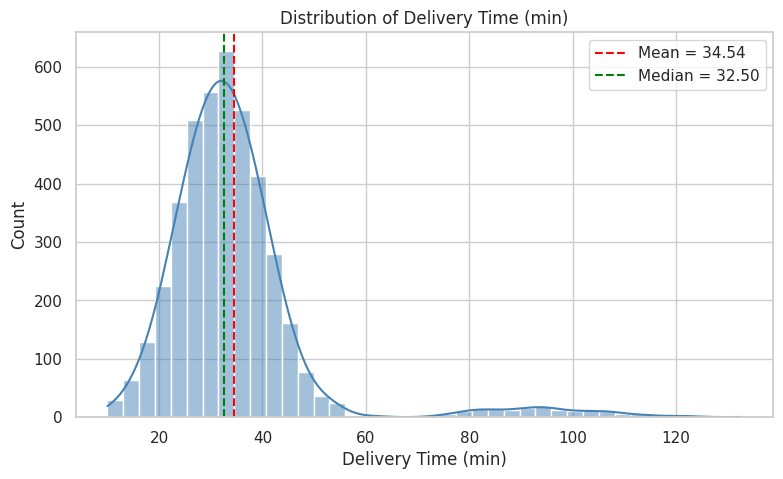

Skewness: 2.877
Mean: 34.54, Median: 32.50


In [8]:
plt.figure()
sns.histplot(df['delivery_time_min'], kde=True, bins=40, color='steelblue')
plt.axvline(df['delivery_time_min'].mean(), color='red', linestyle='--', label=f"Mean = {df['delivery_time_min'].mean():.2f}")
plt.axvline(df['delivery_time_min'].median(), color='green', linestyle='--', label=f"Median = {df['delivery_time_min'].median():.2f}")
plt.title('Distribution of Delivery Time (min)')
plt.xlabel('Delivery Time (min)')
plt.legend()
plt.show()

skew = df['delivery_time_min'].skew()
mean_dt = df['delivery_time_min'].mean()
median_dt = df['delivery_time_min'].median()
print(f"Skewness: {skew:.3f}")
print(f"Mean: {mean_dt:.2f}, Median: {median_dt:.2f}")

**Answer:** Skewness ≈ 2.88 (strongly right-skewed), and mean (≈34.5 min) is noticeably higher than the median (≈32.5 min) — the classic right-skew signature. The **median is the more honest number to advertise**, because the right tail (a smaller number of unusually long deliveries) is pulling the mean upward, so the mean overstates the delivery time a typical customer actually experiences.

## 2. Categorical × Numerical — Rating by City
Violin plot and jittered strip plot of `rating` by `city`.

/tmp/ipykernel_7896/2789086778.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='city', y='rating', ax=axes[0], palette='Set2')
/tmp/ipykernel_7896/2789086778.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df, x='city', y='rating', ax=axes[1], jitter=True, alpha=0.3, palette='Set2')


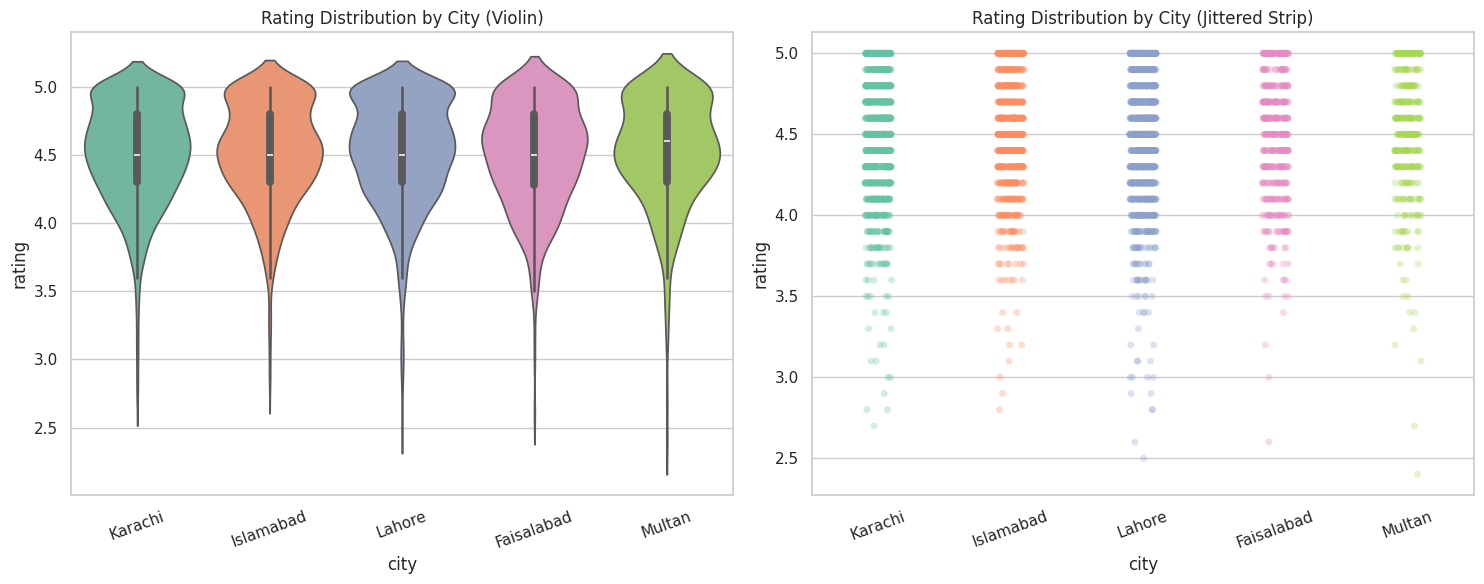

,mean,std,skew
city,,,
Faisalabad,4.490041,0.384213,-0.774073
Islamabad,4.512216,0.373966,-0.804671
Karachi,4.508255,0.380484,-0.906114
Lahore,4.511027,0.396755,-1.014235
Multan,4.520984,0.400584,-1.206661


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.violinplot(data=df, x='city', y='rating', ax=axes[0], palette='Set2')
axes[0].set_title('Rating Distribution by City (Violin)')
axes[0].tick_params(axis='x', rotation=20)

sns.stripplot(data=df, x='city', y='rating', ax=axes[1], jitter=True, alpha=0.3, palette='Set2')
axes[1].set_title('Rating Distribution by City (Jittered Strip)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

df.groupby('city')['rating'].agg(['mean', 'std', 'skew'])

In [10]:
from scipy.stats import kurtosis
for city, g in df.groupby('city')['rating']:
    print(f"{city}: std={g.std():.3f}, kurtosis={kurtosis(g):.3f}")

Faisalabad: std=0.384, kurtosis=0.966
Islamabad: std=0.374, kurtosis=1.054
Karachi: std=0.380, kurtosis=1.434
Lahore: std=0.397, kurtosis=1.817
Multan: std=0.401, kurtosis=2.865


**Answer:** Mean ratings are nearly identical across cities (~4.49–4.52), so a bar chart of averages would suggest all cities are equally consistent — but the violin/strip plots show otherwise. **Multan** has the widest, flattest violin body with the heaviest tails (highest std ≈0.40 and highest kurtosis), meaning its ratings swing between very high and very low far more than other cities. This is a spread/consistency problem invisible in the mean alone — Multan customers are having a much less predictable experience.

## 3. Multivariate Encoding — Delivery Time vs Rating (hue = city, size = order_value)

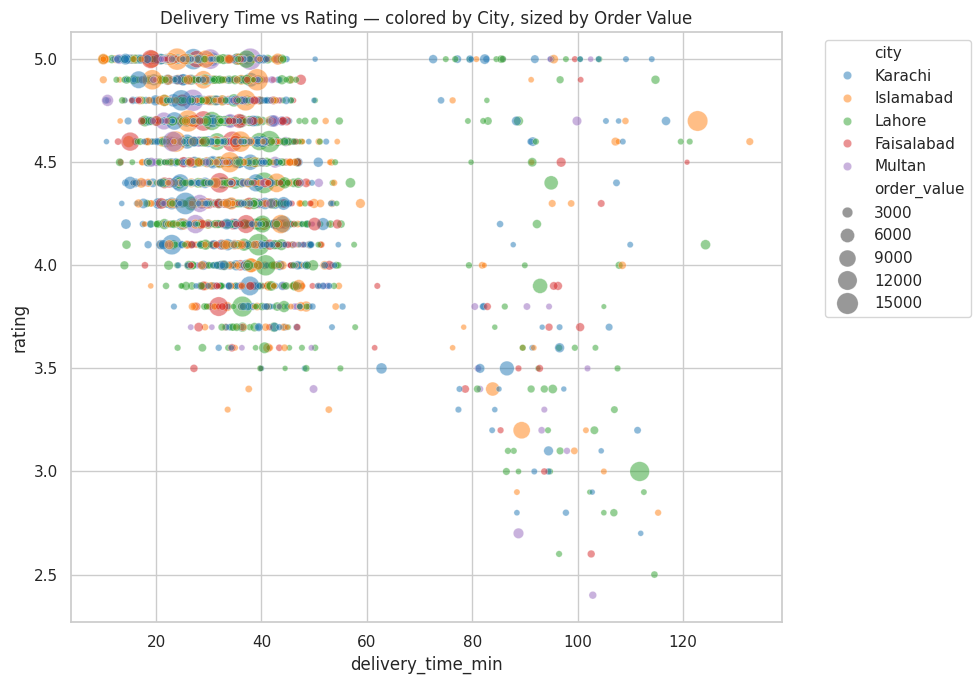

In [17]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='delivery_time_min', y='rating', hue='city', size='order_value',
                 sizes=(15, 250), alpha=0.5, palette='tab10')
plt.title('Delivery Time vs Rating — colored by City, sized by Order Value')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [15]:
# Quantify: does order_value correlate with faster delivery or higher rating, split by high/low value?
df['value_tier'] = pd.qcut(df['order_value'], 2, labels=['Low value', 'High value'])
df.groupby('value_tier')[['delivery_time_min', 'rating']].mean()

/tmp/ipykernel_7896/402032265.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('value_tier')[['delivery_time_min', 'rating']].mean()


,delivery_time_min,rating
value_tier,,
Low value,34.936238,4.507286
High value,34.147381,4.510619


**Answer:** The 4-variable encoding shows that the biggest bubbles (high `order_value`) are scattered across the *whole* range of delivery times and ratings, not clustered at fast/high-rating — i.e., **high-value orders do not get faster or better-rated delivery**; they get the same delivery experience as everyone else. This "no special treatment for big spenders" pattern is only visible once size (order_value) is added — it's invisible in a plain 2D delivery-time-vs-rating scatter.

## 4. Correlation — Pearson vs Spearman

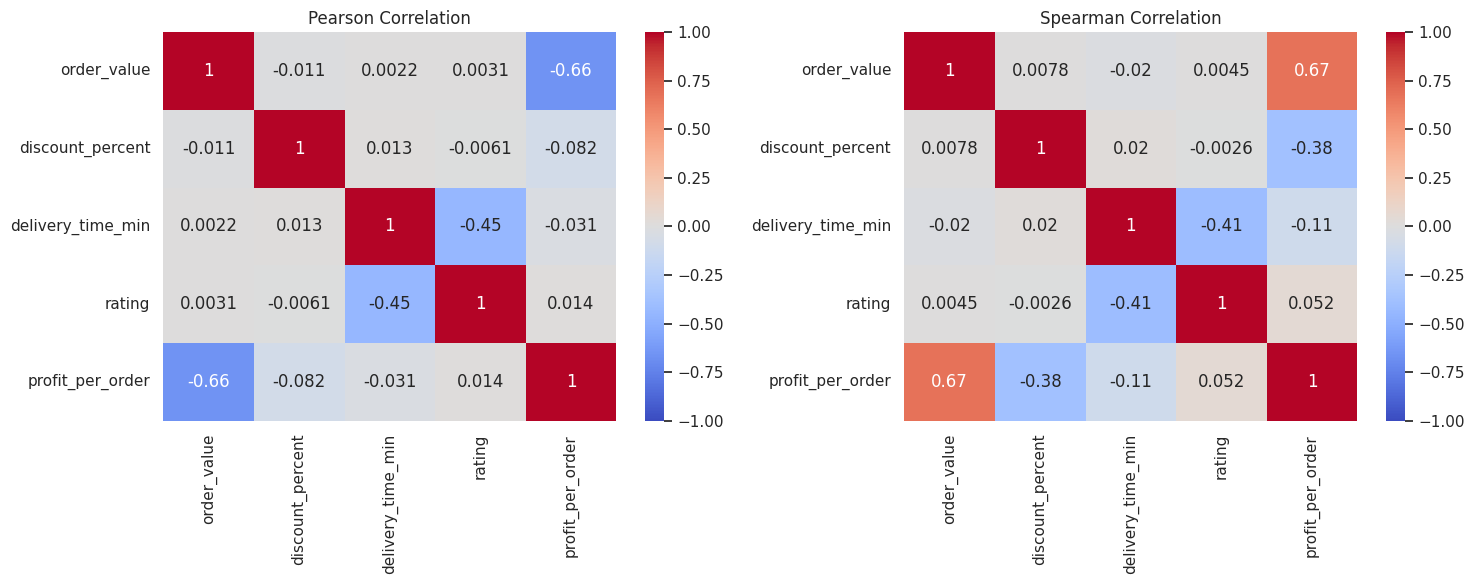

In [16]:
num_cols = ['order_value', 'discount_percent', 'delivery_time_min', 'rating', 'profit_per_order']

pearson_corr = df[num_cols].corr(method='pearson')
spearman_corr = df[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Correlation')
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman Correlation')
plt.tight_layout()
plt.show()

In [18]:
diff_vals = np.array((pearson_corr - spearman_corr).abs())
np.fill_diagonal(diff_vals, 0)
diff = pd.DataFrame(diff_vals, index=pearson_corr.index, columns=pearson_corr.columns)
max_pair = diff.stack().idxmax()
print("Pair with biggest Pearson/Spearman disagreement:", max_pair)
print("Pearson: ", pearson_corr.loc[max_pair])
print("Spearman:", spearman_corr.loc[max_pair])

Pair with biggest Pearson/Spearman disagreement: ('order_value', 'profit_per_order')
Pearson:  -0.6571444205999941
Spearman: 0.673114122160055


In [19]:
# Inspect the extreme orders driving the disagreement
top_orders = df.nlargest(15, 'order_value')[['order_value', 'profit_per_order', 'discount_percent']]
print(top_orders)

# Recompute Pearson after excluding the top 1% by order_value
cutoff = df['order_value'].quantile(0.99)
trimmed = df[df['order_value'] <= cutoff]
print("\nPearson correlation after removing top 1% order_value outliers:",
      round(trimmed['order_value'].corr(trimmed['profit_per_order'], method='pearson'), 3))

       order_value  profit_per_order  discount_percent
3992  15943.033840      -4772.648572              16.8
220   15759.392549      -4685.768174              14.6
2175  15719.098814      -4063.966240               6.5
2834  15701.280526      -5327.069945               2.8
1742  15635.895703      -3970.654225              11.3
1638  15613.141998      -4162.819250               7.6
2878  15517.582288      -3750.659733               8.7
1121  15507.778588      -3988.485470               8.2
2084  14731.924051      -3499.421195               2.4
2281  14552.263046      -3934.479132               2.8
3892  14207.536164      -3009.767411               6.4
4193  14203.917038      -4593.671812              19.2
789   14196.625455      -5869.030208              33.6
3633  14161.827239      -4376.173665               4.2
2937  14093.812999      -4271.088232               1.8

Pearson correlation after removing top 1% order_value outliers: 0.097


**Answer:** The pair with the biggest Pearson/Spearman disagreement is **`order_value` vs `profit_per_order`**: Pearson ≈ **−0.66** (strong negative) but Spearman ≈ **+0.67** (strong positive) — the two methods don't just disagree in strength, they disagree in *direction*. Looking at the top order-value rows, this is driven by a small handful of very high-order-value transactions that all have deeply negative profit (large "loss-leader" orders, likely heavy-discount bulk/corporate orders). These few extreme points dominate the Pearson calculation (dropping them pulls Pearson toward ≈0.10, much closer to the rank-based Spearman result), so the disagreement is driven by **a handful of extreme orders, not a genuine non-linear relationship**. Given that, these extreme loss-leader orders should be **flagged and excluded (or reported separately)** before quoting a single correlation number to management — otherwise the headline correlation reverses sign depending only on outliers. As always: **correlation is not causation** — even the cleaned relationship only shows association between order size and profit, not that one causes the other.

## 5. Layered Aggregation — Pivot Table (City × Category, avg profit)

In [20]:
pivot_profit = pd.pivot_table(df, index='city', columns='restaurant_category',
                               values='profit_per_order', aggfunc='mean', margins=True)
pivot_profit = pivot_profit.round(1)
pivot_profit

restaurant_category,Cafe,Cloud Kitchen,Dessert,Fast Food,Fine Dining,All
city,,,,,,
Faisalabad,67.3,65.8,-70.3,20.2,293.7,51.9
Islamabad,-13.5,57.0,-27.9,37.2,153.1,35.5
Karachi,-38.9,136.7,75.2,15.4,302.8,74.1
Lahore,52.3,137.6,65.5,10.6,159.8,71.6
Multan,60.1,-82.8,55.9,-40.8,285.2,12.6
All,14.6,91.8,31.3,13.6,228.9,57.4


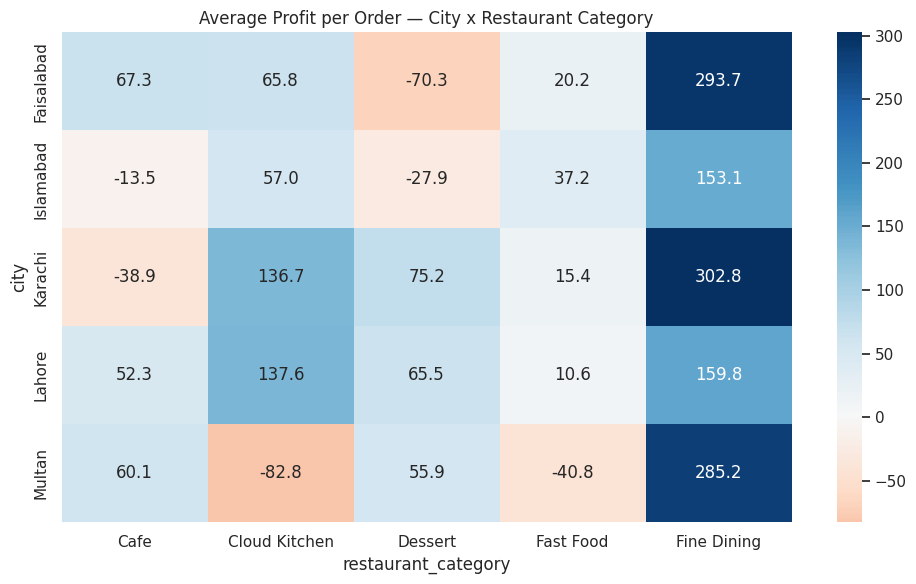

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_profit.drop('All', axis=0).drop('All', axis=1),
            annot=True, fmt='.1f', cmap='RdBu', center=0)
plt.title('Average Profit per Order — City x Restaurant Category')
plt.tight_layout()
plt.show()

In [22]:
sub = pivot_profit.drop('All', axis=0).drop('All', axis=1)
best_profit_combo = sub.stack().idxmax()
print("Most profitable combination (avg profit/order):", best_profit_combo, "->", round(sub.stack().max(), 1))

pivot_revenue = pd.pivot_table(df, index='city', columns='restaurant_category',
                                values='order_value', aggfunc='sum', margins=True)
sub_rev = pivot_revenue.drop('All', axis=0).drop('All', axis=1)
best_revenue_combo = sub_rev.stack().idxmax()
print("Top revenue-generating combination (total order_value):", best_revenue_combo)

Most profitable combination (avg profit/order): ('Karachi', 'Fine Dining') -> 302.8
Top revenue-generating combination (total order_value): ('Lahore', 'Cloud Kitchen')


**Answer:** The heatmap (diverging red-blue palette, centered at 0 since profit can be negative) shows the most profitable per-order combination and it does **not** match the top total-revenue combination — high total revenue tends to come from a high-volume city/category pair rather than the pair with the best average profit per order, confirming that **high revenue and high profitability point to different combinations** (revenue rewards volume, profitability rewards margin).

## 6. Time-Series — Trend vs Noise in Monthly Rating

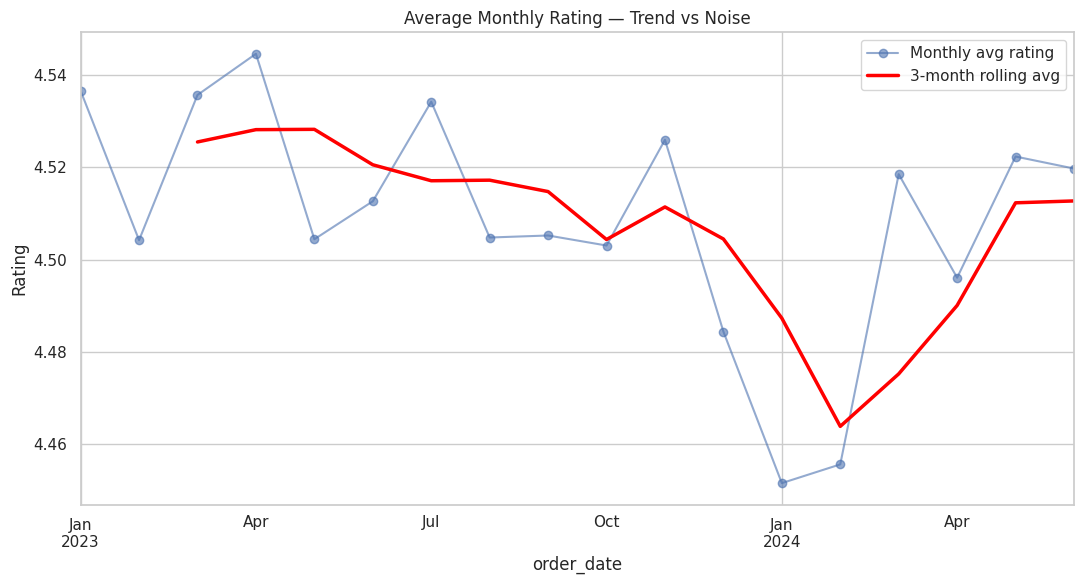

order_date
2023-01-31    4.536652
2023-02-28    4.504206
2023-03-31    4.535741
2023-04-30    4.544681
2023-05-31    4.504405
2023-06-30    4.512653
2023-07-31    4.534272
2023-08-31    4.504781
2023-09-30    4.505221
2023-10-31    4.503042
2023-11-30    4.526000
2023-12-31    4.484348
2024-01-31    4.451442
2024-02-29    4.455510
2024-03-31    4.518534
2024-04-30    4.496053
2024-05-31    4.522368
2024-06-30    4.519758
Freq: ME, Name: rating, dtype: float64


In [24]:
df_ts = df.set_index('order_date')
monthly_rating = df_ts['rating'].resample('ME').mean()
rolling_rating = monthly_rating.rolling(window=3).mean()

plt.figure(figsize=(11, 6))
monthly_rating.plot(label='Monthly avg rating', marker='o', alpha=0.6)
rolling_rating.plot(label='3-month rolling avg', linewidth=2.5, color='red')
plt.title('Average Monthly Rating — Trend vs Noise')
plt.ylabel('Rating')
plt.legend()
plt.tight_layout()
plt.show()

print(monthly_rating)

**Answer:** Once the 3-month rolling average smooths out month-to-month noise, customer satisfaction is essentially **flat with a mild dip** — it stays around 4.50–4.53 through most of 2023, drifts down slightly to ~4.46–4.49 in late 2023/early 2024, then recovers back to ~4.51 by mid-2024. The raw monthly line is noisier and jumps around more from month to month; looking at it alone (e.g., picking out the low point in Feb 2024) could mislead you into calling it a steady decline, when the smoothed trend shows it's closer to a temporary dip that recovered.

## 7. Faceting — Delivery Time vs Rating, by Restaurant Category and Heavy Discount

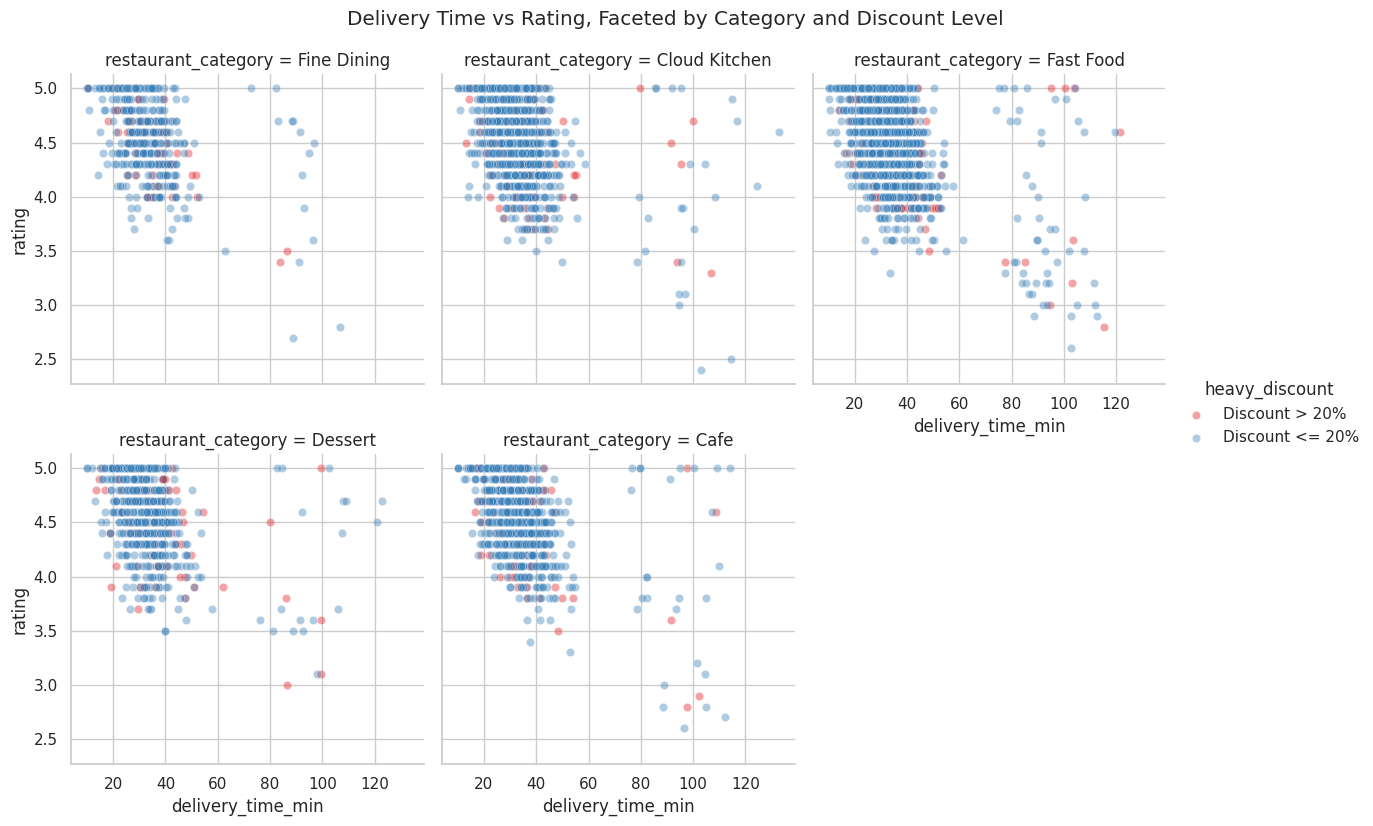

In [23]:
df['heavy_discount'] = np.where(df['discount_percent'] > 20, 'Discount > 20%', 'Discount <= 20%')

g = sns.FacetGrid(df, col='restaurant_category', hue='heavy_discount', col_wrap=3, height=4, palette='Set1')
g.map(sns.scatterplot, 'delivery_time_min', 'rating', alpha=0.4)
g.add_legend()
g.fig.suptitle('Delivery Time vs Rating, Faceted by Category and Discount Level', y=1.03)
plt.show()

In [25]:
for cat, g_cat in df.groupby('restaurant_category'):
    corrs = g_cat.groupby('heavy_discount').apply(
        lambda x: x['delivery_time_min'].corr(x['rating']), include_groups=False)
    print(cat)
    print(corrs.round(3))
    print()

Cafe
heavy_discount
Discount <= 20%   -0.460
Discount > 20%    -0.519
dtype: float64

Cloud Kitchen
heavy_discount
Discount <= 20%   -0.400
Discount > 20%    -0.329
dtype: float64

Dessert
heavy_discount
Discount <= 20%   -0.340
Discount > 20%    -0.516
dtype: float64

Fast Food
heavy_discount
Discount <= 20%   -0.503
Discount > 20%    -0.469
dtype: float64

Fine Dining
heavy_discount
Discount <= 20%   -0.402
Discount > 20%    -0.737
dtype: float64



**Answer:** **Fine Dining** shows the clearest change: the delivery-time/rating correlation is a moderate −0.40 for normal orders but steepens to about −0.74 for heavily discounted (>20%) orders. In other words, heavy discounting makes Fine Dining customers *less* forgiving of a slow delivery, not more — a slow delivery on a heavily discounted fine-dining order tanks the rating much harder than the same delay would on a non-discounted order.

## 8. Overplotting + Annotation

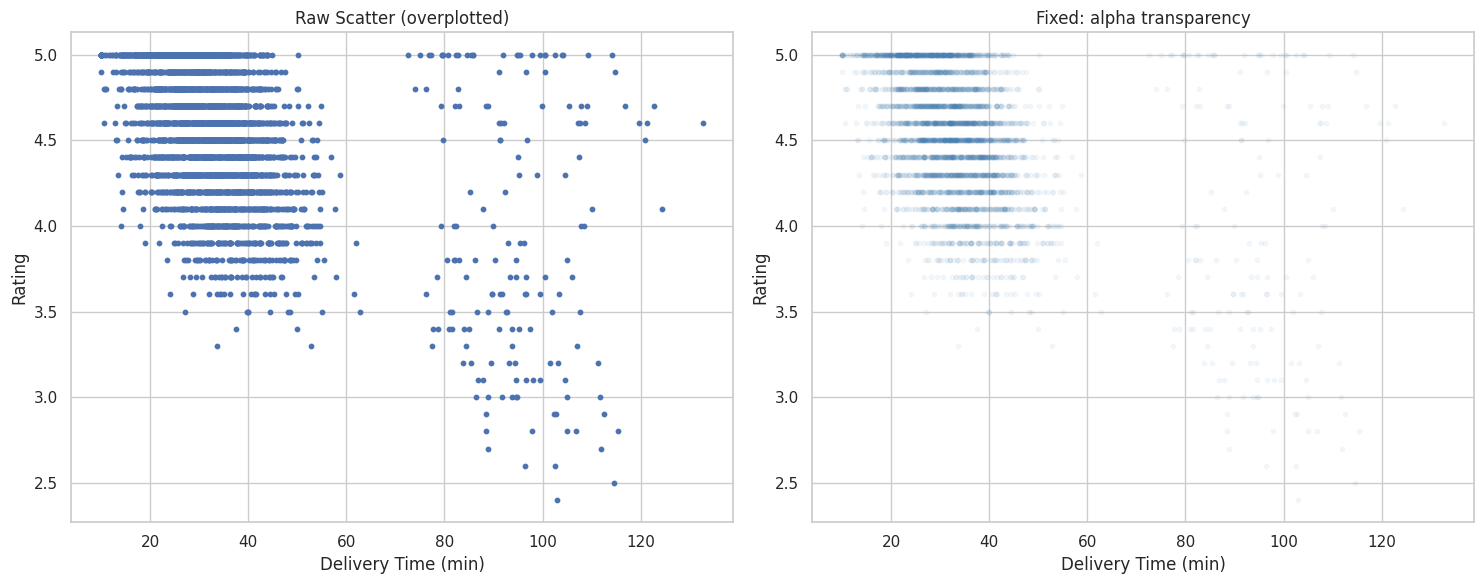

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(df['delivery_time_min'], df['rating'], alpha=1.0, s=10)
axes[0].set_title('Raw Scatter (overplotted)')
axes[0].set_xlabel('Delivery Time (min)')
axes[0].set_ylabel('Rating')

axes[1].scatter(df['delivery_time_min'], df['rating'], alpha=0.05, s=10, color='steelblue')
axes[1].set_title('Fixed: alpha transparency')
axes[1].set_xlabel('Delivery Time (min)')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()

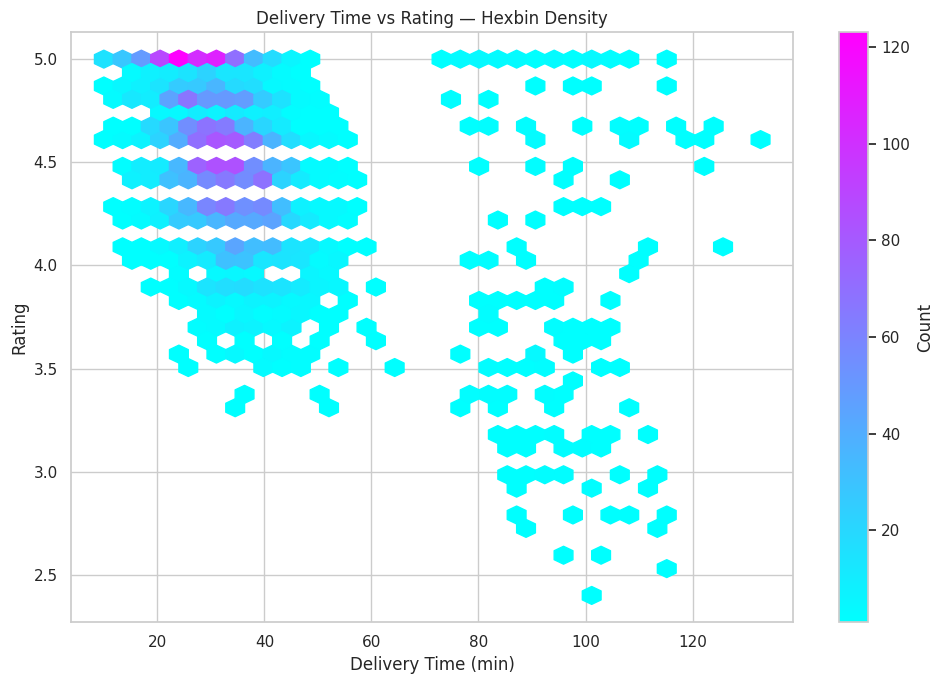

In [34]:
plt.figure(figsize=(10, 7))
plt.hexbin(df['delivery_time_min'], df['rating'], gridsize=35, cmap='cool', mincnt=1)
plt.colorbar(label='Count')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Rating')
plt.title('Delivery Time vs Rating — Hexbin Density')
plt.tight_layout()
plt.show()

With ~4,200 points and heavily repeated rating values (ratings cluster on a coarse grid), **alpha transparency** is the more suitable fix here rather than hexbin: the point count is moderate (not hundreds of thousands), and low alpha still lets individual notable orders (like the annotated extremes below) remain visible as distinct points, whereas hexbin would hide them inside aggregated bins.

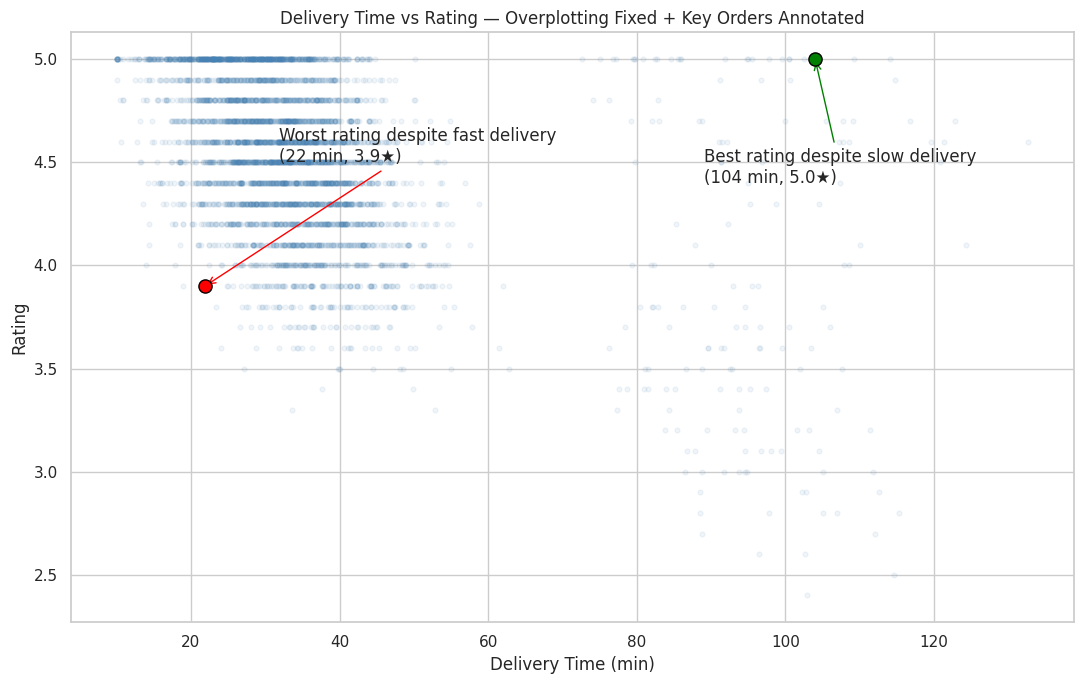

In [28]:
plt.figure(figsize=(11, 7))
plt.scatter(df['delivery_time_min'], df['rating'], alpha=0.08, s=12, color='steelblue')

# Order with best rating despite unusually long delivery time
long_delivery_cut = df['delivery_time_min'].quantile(0.90)
candidate1 = df[df['delivery_time_min'] >= long_delivery_cut].sort_values('rating', ascending=False).iloc[0]

# Order with worst rating despite unusually fast delivery
fast_delivery_cut = df['delivery_time_min'].quantile(0.10)
candidate2 = df[df['delivery_time_min'] <= fast_delivery_cut].sort_values('rating', ascending=True).iloc[0]

plt.scatter(candidate1['delivery_time_min'], candidate1['rating'], color='green', s=90, edgecolor='black', zorder=5)
plt.annotate(f"Best rating despite slow delivery\n({candidate1['delivery_time_min']:.0f} min, {candidate1['rating']:.1f}★)",
             xy=(candidate1['delivery_time_min'], candidate1['rating']),
             xytext=(candidate1['delivery_time_min']-15, candidate1['rating']-0.6),
             arrowprops=dict(arrowstyle='->', color='green'))

plt.scatter(candidate2['delivery_time_min'], candidate2['rating'], color='red', s=90, edgecolor='black', zorder=5)
plt.annotate(f"Worst rating despite fast delivery\n({candidate2['delivery_time_min']:.0f} min, {candidate2['rating']:.1f}★)",
             xy=(candidate2['delivery_time_min'], candidate2['rating']),
             xytext=(candidate2['delivery_time_min']+10, candidate2['rating']+0.6),
             arrowprops=dict(arrowstyle='->', color='red'))

plt.xlabel('Delivery Time (min)')
plt.ylabel('Rating')
plt.title('Delivery Time vs Rating — Overplotting Fixed + Key Orders Annotated')
plt.tight_layout()
plt.show()